# Ejercicio 4: segmentar los objetos de una imagen con YOLOv8

**Juan David Sierra Orozco**
Inteligencia Artificial (SI3003), EAFIT, clase de redes convolucionales

## Enunciado

Usar VGG o YOLOv8 para segmentar los elementos detectados en una imagen. Verificar con fotografías de mascotas, de personas y de elementos de vestir. El usuario carga la imagen y el algoritmo devuelve la imagen segmentada.

## Por qué YOLOv8 y no VGG

**VGG** es un clasificador: recibe una imagen completa y devuelve una etiqueta entre las 1000 categorías de ImageNet (unos 138 millones de parámetros en VGG16). No dice **dónde** está cada objeto ni cuáles píxeles le pertenecen, así que por sí solo no segmenta.

**YOLOv8 tiene una variante de segmentación (`-seg`)** que, para cada objeto, entrega su clase, su caja y una **máscara** con los píxeles exactos que ocupa. Es segmentación **de instancias**: dos personas en la misma foto salen como dos máscaras distintas, no como una sola mancha de "persona".

## Qué devuelve la función

`segmentar(modelo, imagen, conf)` devuelve la **imagen segmentada** (cada objeto con su máscara de color, su contorno y su etiqueta), una segunda versión con **solo los objetos** sobre fondo negro, y los datos de cada detección: clase, confianza, porcentaje de la imagen que ocupa y su máscara.

## Una advertencia sobre "elementos de vestir"

El modelo se entrenó con COCO, que tiene 80 clases. Entre ellas hay animales, personas y solo cinco accesorios (corbata, mochila, cartera, paraguas y maleta), pero **no hay ninguna prenda**: ni camisa, ni vestido, ni zapatos, ni pantalón. Qué tanto cubre esto el enunciado se comprueba en las secciones 7 y 8, no se da por supuesto.

In [1]:
# En Google Colab hay que instalar la libreria una vez (en local ya viene instalada):
# %pip install -q -U ultralytics

import os
import time
import urllib.request
from pathlib import Path

import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

try:
    from ipykernel.kernelbase import StdinNotImplementedError
except ImportError:
    class StdinNotImplementedError(Exception):
        pass

plt.rcParams["figure.dpi"] = 70

---

## 1. Cargar el modelo

`yolov8n-seg.pt` es la versión más pequeña ("nano") de segmentación. Se descarga sola la primera vez. Para máscaras más precisas se puede usar `yolov8s-seg.pt` o `yolov8m-seg.pt`, a cambio de más tiempo por imagen.

In [2]:
MODELO = "yolov8n-seg.pt"
modelo = YOLO(MODELO)

cabeza = modelo.model.model[-1]
parametros = sum(p.numel() for p in modelo.model.parameters())

print("Tarea del modelo       :", modelo.task)
print("Clases que reconoce    :", len(modelo.names))
print(f"Parametros             : {parametros / 1e6:.1f} millones")
print(f"Cabeza de segmentacion : {type(cabeza).__name__}, con {cabeza.nm} prototipos de mascara")

Tarea del modelo       : segment
Clases que reconoce    : 80
Parametros             : 3.4 millones
Cabeza de segmentacion : Segment, con 32 prototipos de mascara


La cabeza de segmentación no dibuja cada máscara desde cero. Aprende **32 mapas prototipo** compartidos por toda la imagen, y para cada objeto detectado predice 32 coeficientes que dicen cómo combinarlos. La máscara de ese objeto es esa combinación lineal de prototipos, recortada a su caja.

---

## 2. Qué puede segmentar

Las 80 clases de COCO, agrupadas según lo que pide el enunciado.

In [3]:
nombres = set(modelo.names.values())

grupos = {
    "mascotas y animales": ["cat", "dog", "bird", "horse", "sheep", "cow", "elephant", "bear", "zebra", "giraffe"],
    "personas":            ["person"],
    "vestir y accesorios": ["tie", "backpack", "handbag", "umbrella", "suitcase"],
    "prendas de ropa":     ["shirt", "dress", "jacket", "pants", "shoe", "hat", "skirt", "sweater", "coat", "jeans"],
}

for grupo, clases in grupos.items():
    esta = [c for c in clases if c in nombres]
    print(f"{grupo:<22}: {len(esta):>2} de {len(clases):>2} estan entre las clases del modelo   {esta}")

mascotas y animales   : 10 de 10 estan entre las clases del modelo   ['cat', 'dog', 'bird', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe']
personas              :  1 de  1 estan entre las clases del modelo   ['person']
vestir y accesorios   :  5 de  5 estan entre las clases del modelo   ['tie', 'backpack', 'handbag', 'umbrella', 'suitcase']
prendas de ropa       :  0 de 10 estan entre las clases del modelo   []


El grupo de **prendas de ropa** da cero de diez. Es el límite más importante del ejercicio: con este modelo no se puede segmentar una camisa o un vestido, porque nunca se le enseñó lo que es. Se vuelve sobre esto en la sección 8.

---

## 3. La función que segmenta

Recibe una imagen y devuelve la imagen segmentada. Cada instancia se pinta con su propio color, así que dos personas se distinguen entre sí.

In [4]:
PALETA = (np.array(matplotlib.colormaps["tab10"].colors) * 255).astype(np.uint8)


def cargar_rgb(ruta, max_lado=1920):
    """Abre cualquier imagen como RGB. Si es muy grande se reduce para que el proceso sea rapido."""
    imagen = Image.open(ruta).convert("RGB")
    if max(imagen.size) > max_lado:
        escala = max_lado / max(imagen.size)
        imagen = imagen.resize((round(imagen.width * escala), round(imagen.height * escala)), Image.LANCZOS)
    return np.asarray(imagen)


def segmentar(modelo, imagen, conf=0.25):
    """Segmenta los objetos de una imagen.

    imagen: ruta de un archivo o arreglo RGB.
    conf  : confianza minima para aceptar una deteccion (entre 0 y 1).
    Devuelve un diccionario con la imagen segmentada, la version con solo los objetos,
    y los datos de cada deteccion.
    """
    rgb = cargar_rgb(imagen) if isinstance(imagen, (str, Path)) else imagen

    inicio = time.time()
    r = modelo(rgb[..., ::-1], conf=conf, retina_masks=True, verbose=False)[0]   # ultralytics espera BGR
    segundos = time.time() - inicio

    alto, ancho = rgb.shape[:2]
    lienzo = rgb.astype(float).copy()
    solo_objetos = np.zeros_like(rgb)
    detecciones, mascaras = [], []

    for i, caja in enumerate(r.boxes):
        mascara = r.masks.data[i].cpu().numpy().astype(bool)       # (alto, ancho), un True por pixel del objeto
        color = PALETA[i % len(PALETA)]
        lienzo[mascara] = 0.45 * lienzo[mascara] + 0.55 * color     # mascara translucida
        solo_objetos[mascara] = rgb[mascara]
        mascaras.append(mascara)
        x1, y1, x2, y2 = [int(v) for v in caja.xyxy[0].tolist()]
        detecciones.append(dict(id=i + 1, clase=modelo.names[int(caja.cls[0])], confianza=float(caja.conf[0]),
                                area_pct=100 * mascara.sum() / (alto * ancho), caja=(x1, y1, x2, y2),
                                color=tuple(int(c) for c in color)))

    segmentada = lienzo.astype(np.uint8)
    for d, mascara in zip(detecciones, mascaras):
        contornos, _ = cv2.findContours(mascara.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(segmentada, contornos, -1, d["color"], max(2, ancho // 400))
        texto = f"{d['id']} {d['clase']} {d['confianza']:.2f}"
        escala = max(0.5, ancho / 1400)
        (tw, th), _ = cv2.getTextSize(texto, cv2.FONT_HERSHEY_SIMPLEX, escala, 2)
        x1, y1 = d["caja"][0], max(d["caja"][1], th + 8)
        cv2.rectangle(segmentada, (x1, y1 - th - 8), (x1 + tw + 6, y1), d["color"], -1)
        cv2.putText(segmentada, texto, (x1 + 3, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, escala, (255, 255, 255), 2, cv2.LINE_AA)

    return dict(original=rgb, segmentada=segmentada, solo_objetos=solo_objetos,
                detecciones=detecciones, mascaras=mascaras, segundos=segundos)


def mostrar_resultado(res, titulo=""):
    """Original, imagen segmentada y solo los objetos, mas la tabla de detecciones."""
    fig, ejes = plt.subplots(1, 3, figsize=(18, 6.3))
    for eje, clave, nombre in zip(ejes, ["original", "segmentada", "solo_objetos"],
                                  ["Original", "Imagen segmentada", "Solo los objetos"]):
        eje.imshow(res[clave])
        eje.set_title(f"{titulo}: {nombre}" if titulo else nombre)
        eje.axis("off")
    plt.tight_layout()
    plt.show()

    if not res["detecciones"]:
        print("No se detecto ningun objeto con esa confianza minima.")
        return
    print(f"{'#':>2} | {'clase':<12} | {'confianza':>9} | {'% de la imagen':>14}")
    print("-" * 46)
    for d in res["detecciones"]:
        print(f"{d['id']:>2} | {d['clase']:<12} | {d['confianza']:>9.2f} | {d['area_pct']:>13.1f}%")
    print(f"\n{len(res['detecciones'])} objetos en {res['segundos'] * 1000:.0f} ms")

---

## 4. Imágenes de prueba

Se descargan al ejecutar, así que el notebook funciona sin archivos previos. Son fotos de ejemplo de uso común en los tutoriales de estas librerías, más una que ya viene incluida con matplotlib. Cubren lo que pide el enunciado: mascotas, personas y accesorios de vestir.

In [5]:
CARPETA = Path("imagenes_prueba")
CARPETA.mkdir(exist_ok=True)

MUESTRAS = {
    1: ("perro", "mascota", "https://github.com/pytorch/hub/raw/master/images/dog.jpg", "perro.jpg"),
    2: ("gato", "mascota",
        "https://raw.githubusercontent.com/scikit-image/scikit-image/v0.25.0/skimage/data/chelsea.png", "gato.png"),
    3: ("dos personas con corbata", "personas y vestir", "https://ultralytics.com/images/zidane.jpg", "personas_corbata.jpg"),
    4: ("calle con un bus", "personas y objetos", "https://ultralytics.com/images/bus.jpg", "calle_bus.jpg"),
    5: ("persona de uniforme", "personas y vestir", None, "uniforme.jpg"),      # viene incluida con matplotlib
}

RUTAS = {}
for numero, (nombre, categoria, url, archivo) in MUESTRAS.items():
    destino = CARPETA / archivo
    if not destino.exists():
        if url is None:
            origen = Path(matplotlib.get_data_path()) / "sample_data" / "grace_hopper.jpg"
            destino.write_bytes(origen.read_bytes())
        else:
            peticion = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(peticion, timeout=30) as respuesta:
                destino.write_bytes(respuesta.read())
    RUTAS[numero] = str(destino)
    ancho, alto = Image.open(destino).size
    print(f"{numero}) {nombre:<26} [{categoria:<19}] {ancho}x{alto}")

1) perro                      [mascota            ] 1546x1213
2) gato                       [mascota            ] 451x300
3) dos personas con corbata   [personas y vestir  ] 1280x720
4) calle con un bus           [personas y objetos ] 810x1080
5) persona de uniforme        [personas y vestir  ] 512x600


---

## 5. Probar con las cinco imágenes

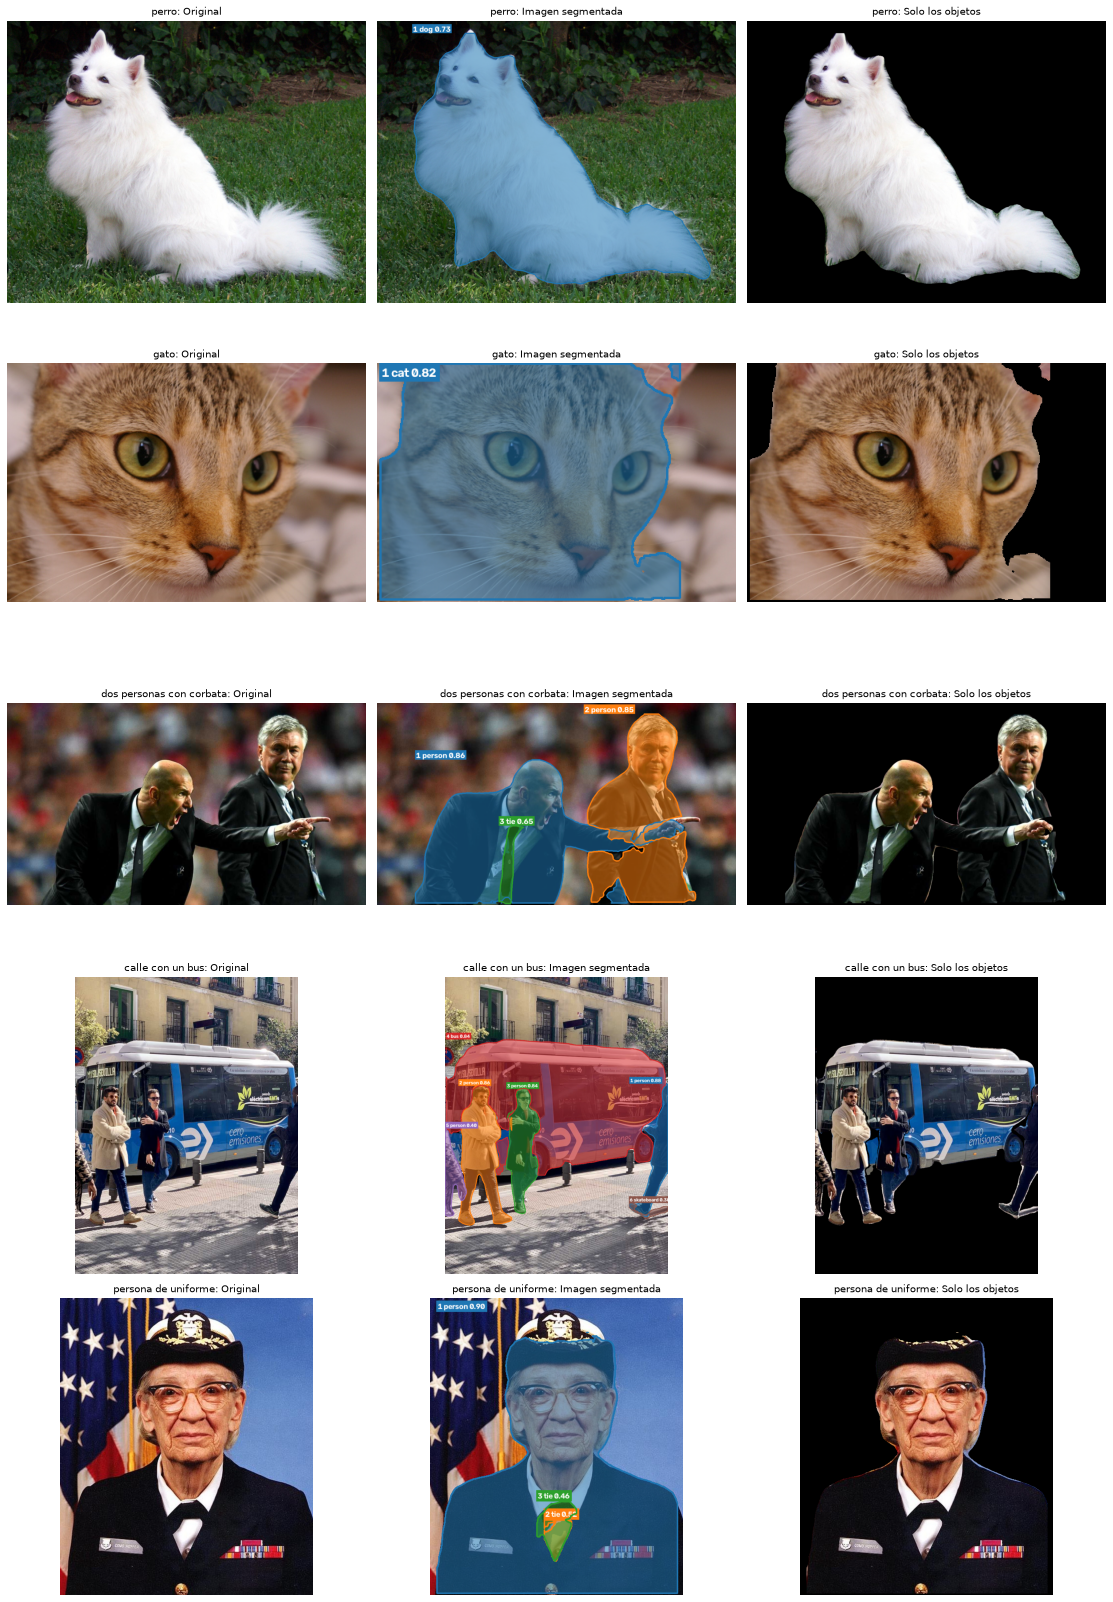

In [6]:
resultados = {}
for numero, (nombre, categoria, _, _) in MUESTRAS.items():
    resultados[numero] = segmentar(modelo, RUTAS[numero])

fig, ejes = plt.subplots(len(MUESTRAS), 3, figsize=(16, 4.6 * len(MUESTRAS)))
for fila, (numero, (nombre, _, _, _)) in enumerate(MUESTRAS.items()):
    for col, (clave, titulo) in enumerate([("original", "Original"), ("segmentada", "Imagen segmentada"),
                                           ("solo_objetos", "Solo los objetos")]):
        ejes[fila, col].imshow(resultados[numero][clave])
        ejes[fila, col].set_title(f"{nombre}: {titulo}", fontsize=10)
        ejes[fila, col].axis("off")
plt.tight_layout()
plt.show()

In [7]:
from collections import Counter

print(f"{'imagen':<26} | {'categoria':<19} | {'que detecto':<48} | {'ms':>5}")
print("-" * 108)
for numero, (nombre, categoria, _, _) in MUESTRAS.items():
    r = resultados[numero]
    cuenta = Counter(d["clase"] for d in r["detecciones"])
    resumen = ", ".join(f"{c} x{n}" for c, n in cuenta.items())
    print(f"{nombre:<26} | {categoria:<19} | {resumen:<48} | {r['segundos'] * 1000:>5.0f}")

imagen                     | categoria           | que detecto                                      |    ms
------------------------------------------------------------------------------------------------------------
perro                      | mascota             | dog x1                                           |   682
gato                       | mascota             | cat x1                                           |    31
dos personas con corbata   | personas y vestir   | person x2, tie x1                                |    29
calle con un bus           | personas y objetos  | person x4, bus x1, skateboard x1                 |    37
persona de uniforme        | personas y vestir   | person x1, tie x2                                |    44


Las mascotas y las personas se segmentan bien: las máscaras siguen el contorno real del animal y de cada persona, y la versión de "solo los objetos" recorta limpio el pelaje del perro sobre el pasto. En la foto de las dos personas cada una recibe su propia máscara y su propio color, que es lo que distingue segmentación de instancias de una segmentación que solo marcara "hay gente".

El tiempo por imagen es de decenas de milisegundos, salvo la primera llamada, que incluye la inicialización del modelo. Depende del equipo.

---

## 6. Cada objeto por separado

Como cada instancia tiene su máscara, se puede **recortar** cada objeto y dejarlo sobre fondo blanco. Aquí se ve algo que un detector de cajas no podría hacer: separar la corbata de la persona que la lleva.

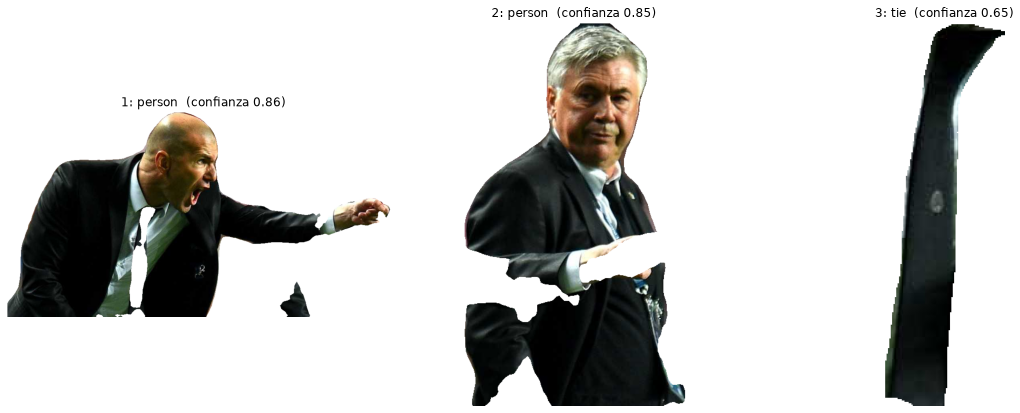

In [8]:
def recortes(res):
    """Cada objeto detectado, recortado con su mascara sobre fondo blanco."""
    piezas = []
    for d, mascara in zip(res["detecciones"], res["mascaras"]):
        x1, y1, x2, y2 = d["caja"]
        fondo_blanco = np.full_like(res["original"], 255)
        pieza = np.where(mascara[..., None], res["original"], fondo_blanco)[y1:y2, x1:x2]
        piezas.append((d, pieza))
    return piezas


piezas = recortes(resultados[3])
fig, ejes = plt.subplots(1, len(piezas), figsize=(5.5 * len(piezas), 6))
for eje, (d, pieza) in zip(np.atleast_1d(ejes), piezas):
    eje.imshow(pieza)
    eje.set_title(f"{d['id']}: {d['clase']}  (confianza {d['confianza']:.2f})")
    eje.axis("off")
plt.tight_layout()
plt.show()

---

## 7. Elementos de vestir: hasta dónde llega el modelo

Lo que sí hay en COCO son las corbatas. En la foto de las dos personas se detectó una sola, la de la persona de la izquierda, aunque las dos llevan corbata. La confianza mínima (`conf`) decide cuántas se aceptan. Se compara con tres valores.

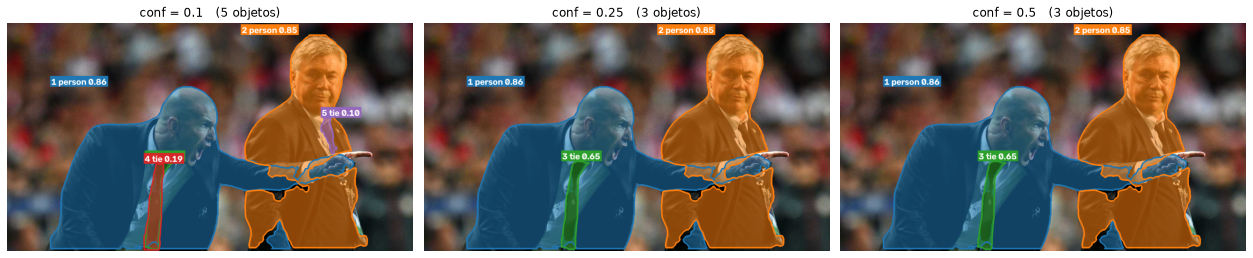

conf = 0.1: [(1, 'person', 0.86), (2, 'person', 0.85), (3, 'tie', 0.65), (4, 'tie', 0.19), (5, 'tie', 0.1)]
conf = 0.25: [(1, 'person', 0.86), (2, 'person', 0.85), (3, 'tie', 0.65)]
conf = 0.5: [(1, 'person', 0.86), (2, 'person', 0.85), (3, 'tie', 0.65)]


In [9]:
confianzas = [0.10, 0.25, 0.50]
por_umbral = {c: segmentar(modelo, RUTAS[3], conf=c) for c in confianzas}

fig, ejes = plt.subplots(1, 3, figsize=(18, 5.5))
for eje, c in zip(ejes, confianzas):
    eje.imshow(por_umbral[c]["segmentada"])
    eje.set_title(f"conf = {c}   ({len(por_umbral[c]['detecciones'])} objetos)")
    eje.axis("off")
plt.tight_layout()
plt.show()

for c in confianzas:
    lista = [(d["id"], d["clase"], round(d["confianza"], 2)) for d in por_umbral[c]["detecciones"]]
    print(f"conf = {c}: {lista}")

In [10]:
def superposicion(a, b):
    """Interseccion sobre union entre dos mascaras: 0 no se tocan, 1 son la misma."""
    return (a & b).sum() / (a | b).sum()


r = por_umbral[0.10]
corbatas = [(d["id"], m) for d, m in zip(r["detecciones"], r["mascaras"]) if d["clase"] == "tie"]
personas = [(d["id"], m) for d, m in zip(r["detecciones"], r["mascaras"]) if d["clase"] == "person"]

print("Superposicion entre las corbatas detectadas con conf = 0.10:")
for i in range(len(corbatas)):
    for j in range(i + 1, len(corbatas)):
        print(f"   corbata {corbatas[i][0]} contra corbata {corbatas[j][0]}: {superposicion(corbatas[i][1], corbatas[j][1]):.2f}")

print("\nPorcentaje de cada corbata que cae dentro de cada persona:")
for id_c, m_c in corbatas:
    for id_p, m_p in personas:
        print(f"   corbata {id_c} dentro de la persona {id_p}: {100 * (m_c & m_p).sum() / m_c.sum():.0f}%")

Superposicion entre las corbatas detectadas con conf = 0.10:
   corbata 3 contra corbata 4: 0.85
   corbata 3 contra corbata 5: 0.00
   corbata 4 contra corbata 5: 0.00

Porcentaje de cada corbata que cae dentro de cada persona:
   corbata 3 dentro de la persona 1: 28%
   corbata 3 dentro de la persona 2: 0%
   corbata 4 dentro de la persona 1: 31%
   corbata 4 dentro de la persona 2: 0%
   corbata 5 dentro de la persona 1: 0%
   corbata 5 dentro de la persona 2: 100%


Bajar la confianza a 0.10 hace aparecer la corbata de la persona de la derecha, pero al mismo tiempo aparece una **segunda detección sobre la corbata que ya se había encontrado**: las dos máscaras se superponen en 0.85 (1 sería idénticas). La corbata nueva cae por completo dentro de la persona de la derecha, así que sí es la que faltaba. Es el compromiso de siempre en detección: con un umbral alto se pierden objetos difíciles, con uno bajo entran duplicados y falsos positivos. No hay un valor correcto para todas las imágenes.

En la foto de la persona de uniforme pasa algo parecido: **la misma zona del cuello sale en dos detecciones de corbata** que se superponen solo a medias, una más pequeña sobre el nudo y otra más grande sobre el cuerpo.

corbata 2: confianza 0.52, ocupa 0.94% de la imagen
corbata 3: confianza 0.46, ocupa 1.76% de la imagen
superposicion entre las dos: 0.48


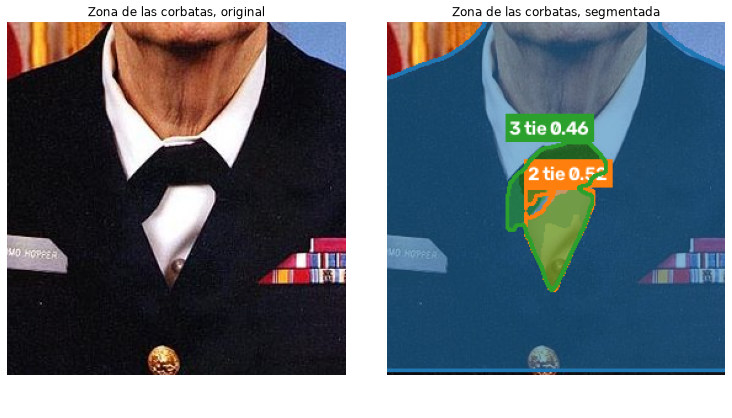

In [11]:
uniforme = resultados[5]
corbatas_uniforme = [(d, m) for d, m in zip(uniforme["detecciones"], uniforme["mascaras"]) if d["clase"] == "tie"]

for d, _ in corbatas_uniforme:
    print(f"corbata {d['id']}: confianza {d['confianza']:.2f}, ocupa {d['area_pct']:.2f}% de la imagen")
if len(corbatas_uniforme) == 2:
    print(f"superposicion entre las dos: {superposicion(corbatas_uniforme[0][1], corbatas_uniforme[1][1]):.2f}")

# Zoom centrado en las cajas de las corbatas, con un margen alrededor.
cajas = [d["caja"] for d, _ in corbatas_uniforme]
zx1, zy1 = min(c[0] for c in cajas), min(c[1] for c in cajas)
zx2, zy2 = max(c[2] for c in cajas), max(c[3] for c in cajas)
margen = int(0.8 * max(zx2 - zx1, zy2 - zy1))

fig, ejes = plt.subplots(1, 2, figsize=(11, 6))
for eje, clave, titulo in [(ejes[0], "original", "Zona de las corbatas, original"),
                           (ejes[1], "segmentada", "Zona de las corbatas, segmentada")]:
    eje.imshow(uniforme[clave])
    eje.set_xlim(zx1 - margen, zx2 + margen)
    eje.set_ylim(zy2 + margen, zy1 - margen)
    eje.set_title(titulo)
    eje.axis("off")
plt.tight_layout()
plt.show()

---

## 8. Lo que no cubre: las prendas

Se cumplió lo que el modelo puede hacer (mascotas, personas y corbatas), pero conviene decir con claridad lo que no. En la foto de la persona de uniforme, el único objeto grande que aparece es `person`: la chaqueta, la camisa y la gorra **no se segmentan como prendas**, quedan dentro de la máscara de la persona.

| Lo que pide el enunciado | Qué lo cubre | Resultado |
|---|---|---|
| Mascotas | `cat`, `dog`, `bird`, `horse`, `sheep`... | Funciona bien |
| Personas | `person` | Funciona bien, una máscara por persona |
| Accesorios de vestir | `tie`, `backpack`, `handbag`, `umbrella`, `suitcase` | Funciona con corbatas; depende de la confianza |
| Prendas (camisa, vestido, zapatos, pantalón) | Ninguna clase | **No se puede** con este modelo |

Para segmentar prendas hay que **reentrenar** el modelo con un conjunto de datos de moda con máscaras por prenda, que es el mismo procedimiento del notebook `Lecture_08_Yolo_training_own_data` de la clase: se parte de `yolov8n-seg.pt` y se ajusta con imágenes etiquetadas de camisas, vestidos, etc. Aquí no se hizo, y el notebook no debe presentarse como si lo cubriera.

---

## 9. El script interactivo: el usuario carga la imagen

Esta función junta todo. Pide la imagen (una de las de prueba, la ruta de un archivo propio, o `subir` para cargarla desde el navegador en Google Colab) y la confianza mínima, segmenta, muestra el resultado, **guarda la imagen segmentada** en la carpeta `resultados/` y la devuelve.

Se valida lo que el usuario escribe: si el archivo no existe o la confianza no es un número entre 0 y 1, se avisa y se vuelve a preguntar. En un entorno sin teclado no se queda esperando: usa una imagen de prueba.

In [12]:
def pedir_imagen():
    print("Imagenes de prueba:")
    for numero, (nombre, categoria, _, _) in MUESTRAS.items():
        print(f"  {numero}) {nombre}  [{categoria}]")
    while True:
        texto = input("Numero de una imagen de prueba, ruta de tu archivo o 'subir' (solo Colab) [1]: ").strip().strip("'\"")
        texto = texto or "1"
        if texto.isdigit() and int(texto) in MUESTRAS:
            return RUTAS[int(texto)]
        if texto.lower() == "subir":
            try:
                from google.colab import files
                return next(iter(files.upload()))
            except ImportError:
                print("  'subir' solo funciona en Google Colab.")
                continue
        if os.path.isfile(texto):
            return texto
        print("  No encuentro ese archivo ni ese numero. Intenta de nuevo.")


def pedir_confianza():
    while True:
        texto = input("Confianza minima entre 0 y 1 (Enter = 0.25): ").strip().replace(",", ".")
        if texto == "":
            return 0.25
        try:
            valor = float(texto)
        except ValueError:
            print("  Escribe un numero, por ejemplo 0.25.")
            continue
        if 0 < valor < 1:
            return valor
        print("  Debe estar entre 0 y 1, sin incluirlos.")


def ejecutar_interactivo(ruta=None, conf=None, carpeta_salida="resultados"):
    """Pide la imagen y la confianza, segmenta, muestra, guarda y devuelve la imagen segmentada."""
    try:
        ruta = ruta or pedir_imagen()
        conf = conf or pedir_confianza()
    except (EOFError, StdinNotImplementedError):
        print("\nNo hay entrada por teclado en este entorno. Se usa la imagen de prueba 3 con confianza 0.25.")
        ruta, conf = ruta or RUTAS[3], conf or 0.25

    res = segmentar(modelo, ruta, conf)
    mostrar_resultado(res, Path(ruta).stem)

    Path(carpeta_salida).mkdir(exist_ok=True)
    salida = Path(carpeta_salida) / f"{Path(ruta).stem}_segmentada.png"
    Image.fromarray(res["segmentada"]).save(salida)
    print(f"Imagen segmentada guardada en: {salida}")
    return res["segmentada"]

> **Nota sobre la celda siguiente.** Al ejecutarla, Jupyter pide cada dato en una caja de texto. Las salidas que se ven guardadas vienen de una corrida de ejemplo con respuestas escritas de antemano (se ve el eco de cada una), e incluyen un archivo inexistente y una confianza inválida a propósito, para mostrar cómo se manejan los errores.

Imagenes de prueba:
  1) perro  [mascota]
  2) gato  [mascota]
  3) dos personas con corbata  [personas y vestir]
  4) calle con un bus  [personas y objetos]
  5) persona de uniforme  [personas y vestir]
Numero de una imagen de prueba, ruta de tu archivo o 'subir' (solo Colab) [1]: foto_que_no_existe.jpg
  No encuentro ese archivo ni ese numero. Intenta de nuevo.
Numero de una imagen de prueba, ruta de tu archivo o 'subir' (solo Colab) [1]: 3
Confianza minima entre 0 y 1 (Enter = 0.25): abc
  Escribe un numero, por ejemplo 0.25.
Confianza minima entre 0 y 1 (Enter = 0.25): 0.25


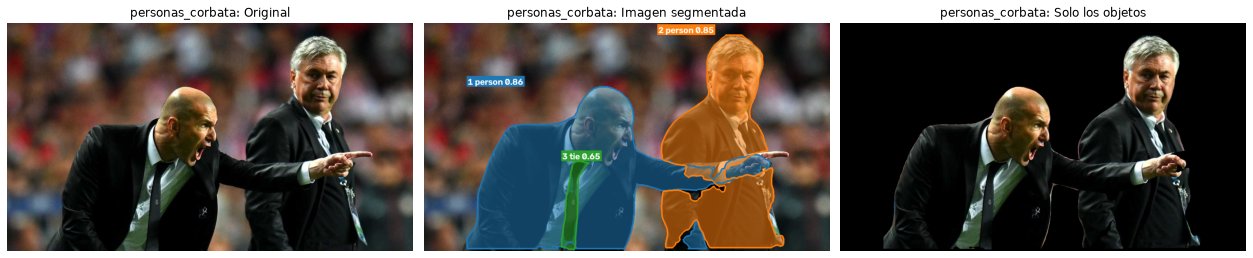

 # | clase        | confianza | % de la imagen
----------------------------------------------
 1 | person       |      0.86 |          24.8%
 2 | person       |      0.85 |          16.7%
 3 | tie          |      0.65 |           1.1%

3 objetos en 31 ms


Imagen segmentada guardada en: resultados/personas_corbata_segmentada.png


In [13]:
imagen_segmentada = ejecutar_interactivo()

---

## 10. Conclusiones

**La segmentación de instancias da mucho más que la detección.** Una caja dice "hay una persona por aquí"; una máscara dice cuáles píxeles son esa persona, y eso permite recortarla, separarla de otra persona que la toca o separar una corbata de quien la lleva. VGG, al ser solo un clasificador, no ofrece nada de esto.

**Mascotas y personas funcionan bien, tal como pide el enunciado.** El modelo más pequeño de la familia ya recorta con limpieza un perro, un gato y varias personas, en decenas de milisegundos.

**Los elementos de vestir se cubren solo en parte.** Las corbatas y otros cuatro accesorios sí; las prendas no, porque COCO no las incluye. Es una limitación de los datos con que se entrenó el modelo, no de la arquitectura, y la forma de resolverla es reentrenar con un conjunto de datos de moda.

**El umbral de confianza es una decisión, no un detalle.** En la misma foto, 0.25 pierde la segunda corbata y 0.10 la encuentra pero agrega un duplicado; en otra foto, la misma zona del cuello salió en dos detecciones de corbata que se superponen a medias. Ningún valor es correcto para todas las imágenes, y por eso el script se lo pregunta al usuario.